In [1]:
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import time
import warnings
warnings.filterwarnings('ignore') # Ẩn các cảnh báo không cần thiết

# Load dữ liệu
PROCESSED_DIR = Path("../data/processed")
X_train = np.load(PROCESSED_DIR / "X_train.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")
X_val   = np.load(PROCESSED_DIR / "X_val.npy")
y_val   = np.load(PROCESSED_DIR / "y_val.npy")
X_test  = np.load(PROCESSED_DIR / "X_test.npy")
y_test  = np.load(PROCESSED_DIR / "y_test.npy")

# Chuẩn hóa và PCA (Chỉ fit trên Train để tránh Data Leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

pca = PCA(n_components=200, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca   = pca.transform(X_val_scaled)
X_test_pca  = pca.transform(X_test_scaled)

print(f"✅ Đã chuẩn bị xong dữ liệu PCA: Train {X_train_pca.shape}")

✅ Đã chuẩn bị xong dữ liệu PCA: Train (1020, 200)


In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score

print("Đang tối ưu K-NN (có thể mất 1-2 phút)...")
start_time = time.time()

param_grid = {
    'n_neighbors': [3, 5, 7, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# Dùng 3-fold CV trên tập Train
grid_knn = GridSearchCV(KNeighborsClassifier(n_jobs=-1), param_grid, 
                        cv=3, scoring='f1_macro', n_jobs=-1)
grid_knn.fit(X_train_pca, y_train)

best_knn = grid_knn.best_estimator_
print(f"✅ Xong! Tham số tốt nhất: {grid_knn.best_params_}")

# Dự đoán
y_val_pred_knn = best_knn.predict(X_val_pca)
y_test_pred_knn = best_knn.predict(X_test_pca)

knn_val_f1 = f1_score(y_val, y_val_pred_knn, average='macro')
knn_test_f1 = f1_score(y_test, y_test_pred_knn, average='macro')

print(f"🔹 K-NN - Val F1: {knn_val_f1:.4f} | Test F1: {knn_test_f1:.4f}")

Đang tối ưu K-NN (có thể mất 1-2 phút)...
✅ Xong! Tham số tốt nhất: {'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'distance'}
🔹 K-NN - Val F1: 0.0315 | Test F1: 0.0324


In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# 1. Decision Tree
print("Đang huấn luyện Decision Tree...")
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train_pca, y_train)
y_val_pred_dt = dt.predict(X_val_pca)
y_test_pred_dt = dt.predict(X_test_pca)
dt_val_f1 = f1_score(y_val, y_val_pred_dt, average='macro')
dt_test_f1 = f1_score(y_test, y_test_pred_dt, average='macro')
print(f"🔹 Decision Tree - Val F1: {dt_val_f1:.4f} | Test F1: {dt_test_f1:.4f}")

# 2. Naive Bayes (Gaussian)
print("\nĐang huấn luyện Naive Bayes...")
nb = GaussianNB()
nb.fit(X_train_pca, y_train)
y_val_pred_nb = nb.predict(X_val_pca)
y_test_pred_nb = nb.predict(X_test_pca)
nb_val_f1 = f1_score(y_val, y_val_pred_nb, average='macro')
nb_test_f1 = f1_score(y_test, y_test_pred_nb, average='macro')
print(f"🔹 Naive Bayes - Val F1: {nb_val_f1:.4f} | Test F1: {nb_test_f1:.4f}")

Đang huấn luyện Decision Tree...
🔹 Decision Tree - Val F1: 0.0318 | Test F1: 0.0251

Đang huấn luyện Naive Bayes...
🔹 Naive Bayes - Val F1: 0.0547 | Test F1: 0.0629


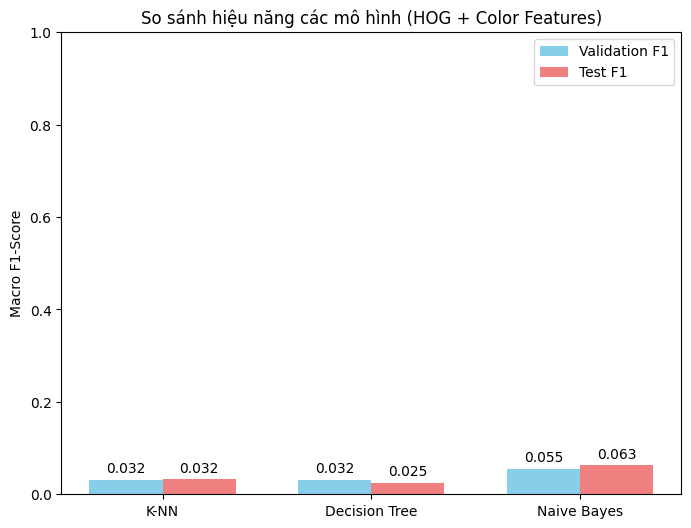

In [4]:
import matplotlib.pyplot as plt

models = ['K-NN', 'Decision Tree', 'Naive Bayes']
val_f1_scores = [knn_val_f1, dt_val_f1, nb_val_f1]
test_f1_scores = [knn_test_f1, dt_test_f1, nb_test_f1]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 6))
rects1 = ax.bar(x - width/2, val_f1_scores, width, label='Validation F1', color='skyblue')
rects2 = ax.bar(x + width/2, test_f1_scores, width, label='Test F1', color='lightcoral')

ax.set_ylabel('Macro F1-Score')
ax.set_title('So sánh hiệu năng các mô hình (HOG + Color Features)')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()
ax.set_ylim(0, 1.0)

# Thêm số liệu lên đầu cột
ax.bar_label(rects1, padding=3, fmt='%.3f')
ax.bar_label(rects2, padding=3, fmt='%.3f')

OUTPUT_DIR = Path("../outputs/figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(OUTPUT_DIR / "model_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

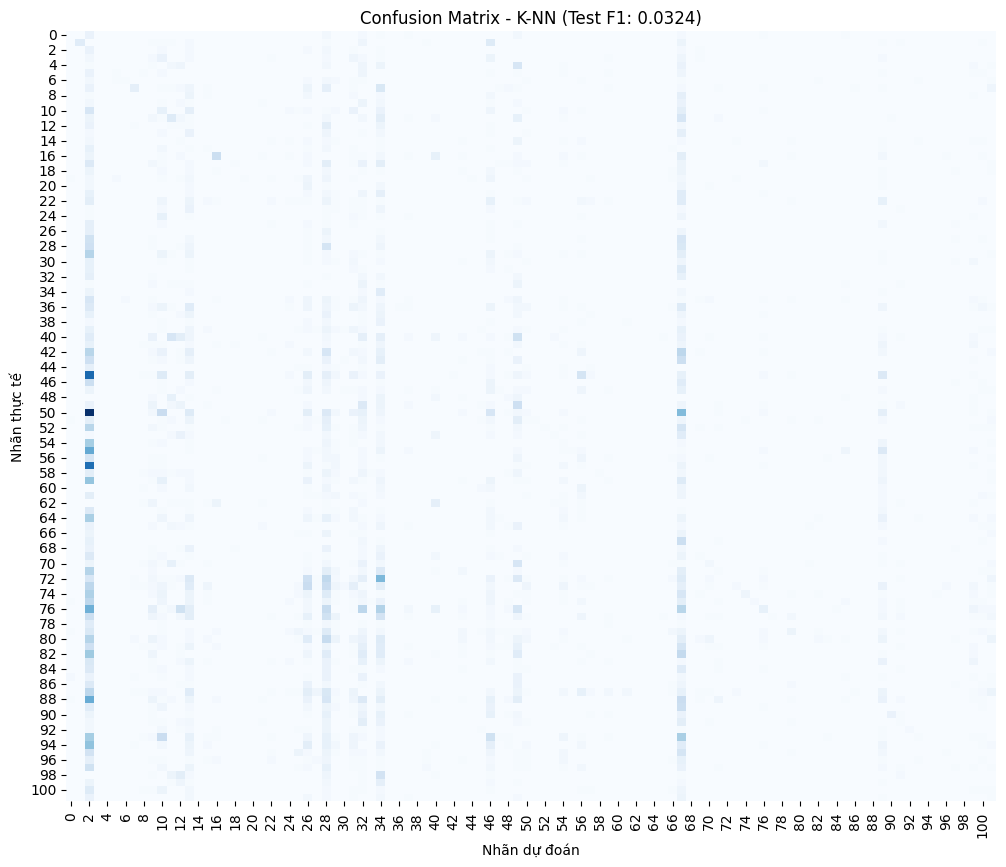

💾 Đã lưu mô hình K-NN tốt nhất vào thư mục models/


In [8]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import joblib

# Vẽ Confusion Matrix cho K-NN (vì đây là mô hình tốt nhất)
cm = confusion_matrix(y_test, y_test_pred_knn)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap='Blues', cbar=False)
plt.title(f"Confusion Matrix - K-NN (Test F1: {knn_test_f1:.4f})")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.savefig(OUTPUT_DIR / "confusion_matrix_knn.png", dpi=300, bbox_inches='tight')
plt.show()

# Lưu mô hình K-NN
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(scaler, MODEL_DIR / "scaler_knn.pkl")
joblib.dump(pca, MODEL_DIR / "pca_knn.pkl")
joblib.dump(best_knn, MODEL_DIR / "knn_model.pkl")
print("💾 Đã lưu mô hình K-NN tốt nhất vào thư mục models/")